In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
import seaborn as sns
from scipy.signal import spectrogram
import pandas as pd
import pywt

In [2]:
spdm_magnitude_data_path = r'9Nov2023\2SubjectsDiagonalMovement\P01A\A'
spdm_phase_data_path = r'9Nov2023\2SubjectsDiagonalMovement\P01A\P'

In [3]:
# Loading Data
magnitude_data = loadmat(spdm_magnitude_data_path)["Data_amplitude"]
phase_data= loadmat(spdm_phase_data_path)["Data_phase"]

In [4]:
magnitude_data.shape, phase_data.shape

((4525, 91), (4525, 91))

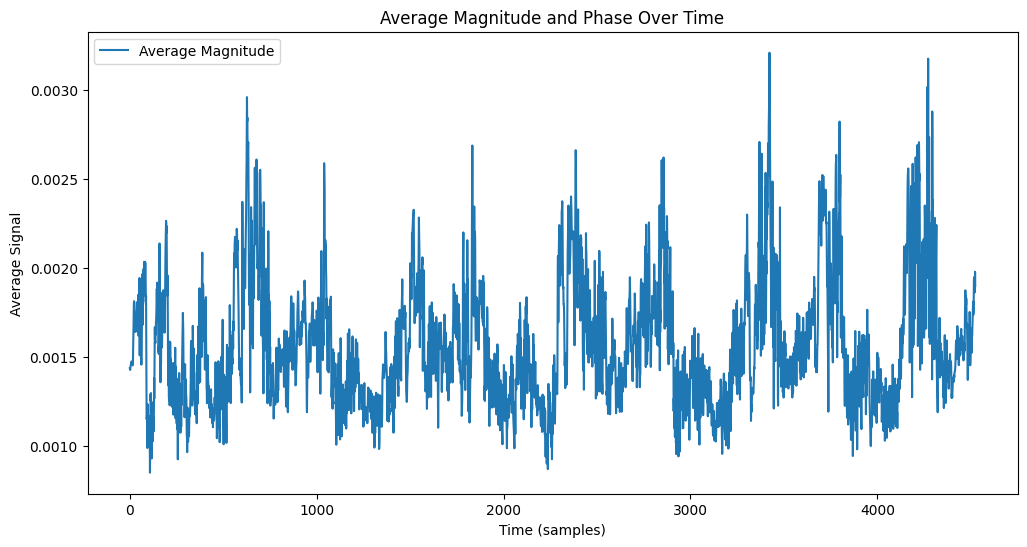

In [5]:
# Averaging across all data points
average_magnitude = np.mean(magnitude_data, axis=1)
average_phase = np.mean(phase_data, axis=1)

# Plotting the average
plt.figure(figsize=(12, 6))
plt.plot(average_magnitude, label='Average Magnitude')
# plt.plot(average_phase, label='Average Phase')
plt.xlabel('Time (samples)')
plt.ylabel('Average Signal')
plt.title('Average Magnitude and Phase Over Time')
plt.legend()
plt.show()

In [6]:
def moving_average(data, window_size):
    """ Computes the moving average using a given window size. """
    return np.convolve(data, np.ones(window_size)/window_size, mode='valid')

In [15]:
# Choose a window size
window_size = 400  # Adjust this based on your data

# Apply the moving average filter
smoothed_magnitude = moving_average(average_magnitude, window_size)
smoothed_phase = moving_average(average_phase, window_size)

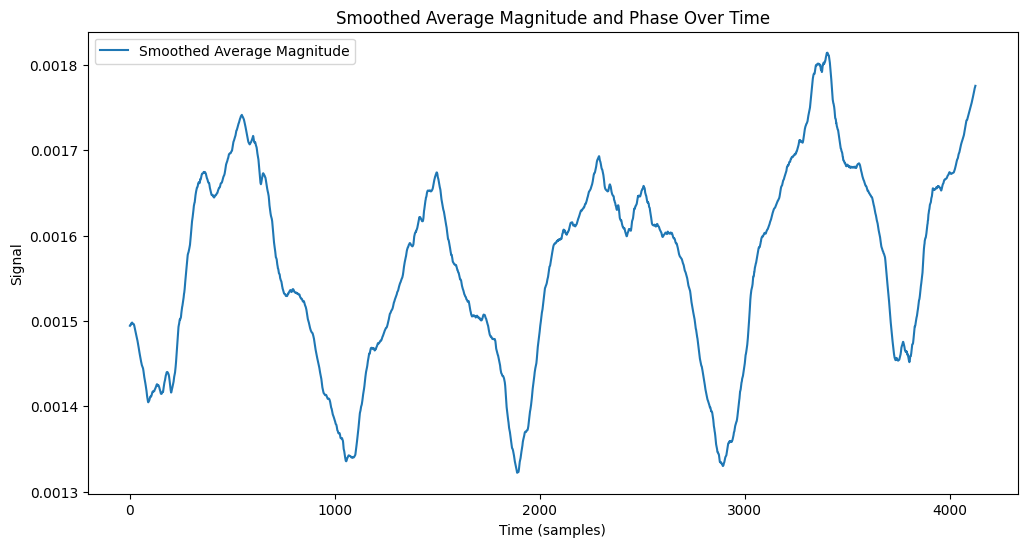

In [16]:
plt.figure(figsize=(12, 6))
plt.plot(smoothed_magnitude, label='Smoothed Average Magnitude')
# plt.plot(smoothed_phase, label='Smoothed Average Phase')
plt.xlabel('Time (samples)')
plt.ylabel('Signal')
plt.title('Smoothed Average Magnitude and Phase Over Time')
plt.legend()
plt.show()

In [17]:
from scipy.signal import butter, filtfilt

def butter_lowpass_filter(data, cutoff, fs, order):
    nyquist = 0.5 * fs
    normal_cutoff = cutoff / nyquist
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    y = filtfilt(b, a, data)
    return y

In [20]:
# Filter requirements
order = 10
fs = 25.15  # sample rate, Hz (you mentioned around 25 samples per second)
cutoff = 0.2  # desired cutoff frequency of the filter, Hz

# Apply the filter
filtered_magnitude = butter_lowpass_filter(average_magnitude, cutoff, fs, order)
filtered_phase = butter_lowpass_filter(average_phase, cutoff, fs, order)

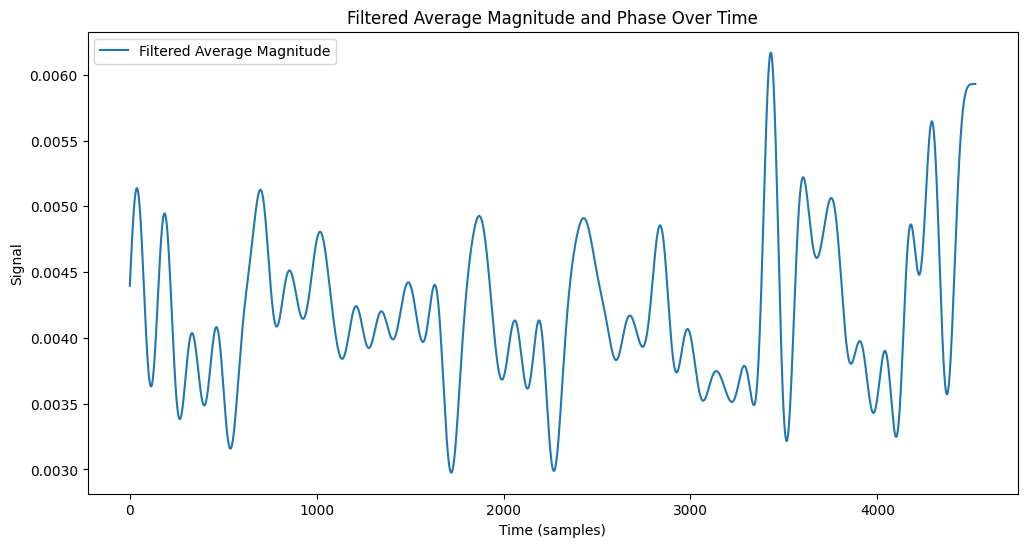

In [21]:
plt.figure(figsize=(12, 6))
plt.plot(filtered_magnitude, label='Filtered Average Magnitude')
# plt.plot(filtered_phase, label='Filtered Average Phase')
plt.xlabel('Time (samples)')
plt.ylabel('Signal')
plt.title('Filtered Average Magnitude and Phase Over Time')
plt.legend()
plt.show()